# Wave Equation, 2D

## Problem
$$
u_{tt} = u_{xx} + u_{yy}, \quad u(x,y,0) = \sin(\pi x)\sin(\pi y), \quad u_t = 0, \quad u = 0 \text{ on the edges}
$$
Exact solution $u = \cos(\sqrt{2}\pi t)\sin(\pi x)\sin(\pi y)$, with period $\sqrt{2}$.

## Discretization
The 2D explicit scheme with the five-point Laplacian. Stability needs $\Delta t \le h/\sqrt{2}$, so $\Delta t = 0.9 h/\sqrt{2}$ is used.

## Code

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.animation import FuncAnimation, PillowWriter
from wave import wave_2d

In [2]:
T_END = np.sqrt(2)
N = 30
h = 1/N
snaps, t, err = wave_2d(N, 0.9*h/np.sqrt(2), T_END)
len(snaps)

68

### Animation

In [3]:
x = np.linspace(0, 1, N+1)
X, Y = np.meshgrid(x, x, indexing='ij')
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection='3d')

def draw(k):
    ax.clear()
    ax.plot_surface(X, Y, snaps[k], cmap='viridis', vmin=-1, vmax=1)
    ax.set_zlim(-1, 1)
    ax.set_title(f"t = {t[k]:.2f}")

ani = FuncAnimation(fig, draw, frames=len(snaps))
ani.save("../figures/10_membrane.gif", writer=PillowWriter(fps=15))
plt.close()

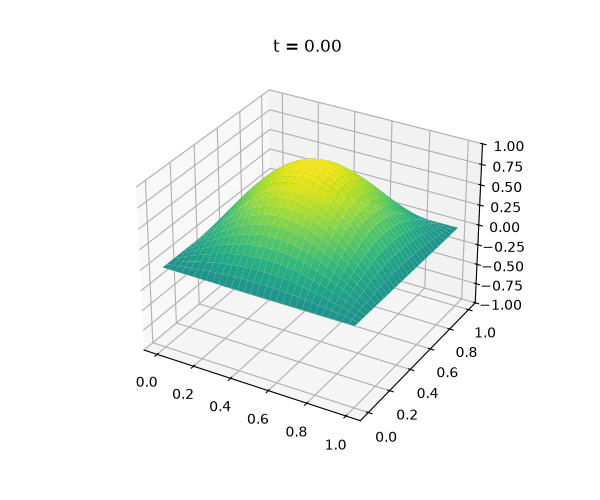

In [4]:
from IPython.display import Image
Image(filename="../figures/10_membrane.gif")

### Error over time

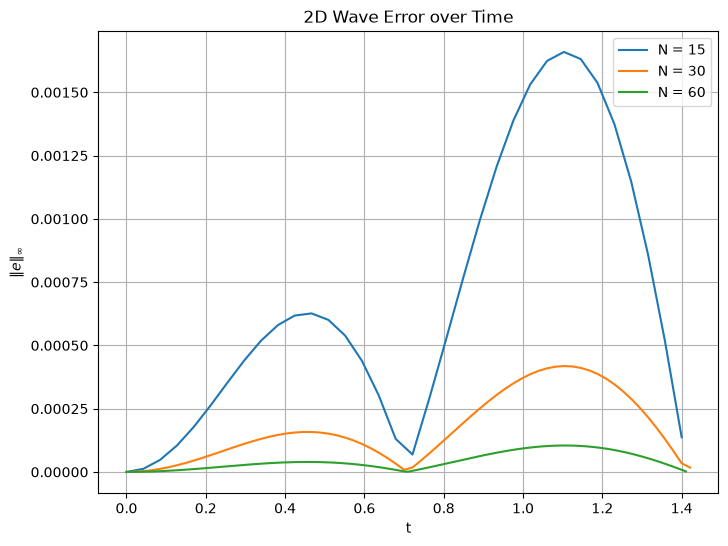

In [5]:
plt.figure(figsize=(8, 6))
for n in [15, 30, 60]:
    s, tt, e = wave_2d(n, 0.9/n/np.sqrt(2), T_END)
    plt.plot(tt, e, label=f"N = {n}")
plt.xlabel("t")
plt.ylabel(r"$\|e\|_\infty$")
plt.title("2D Wave Error over Time")
plt.legend()
plt.grid(True)
plt.savefig("../figures/10_error.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
results = []
for n in [15, 30, 60]:
    s, tt, e = wave_2d(n, 0.9/n/np.sqrt(2), T_END)
    results.append({'h': 1/n, 'max_err': e.max()})
df = pd.DataFrame(results)
df['order'] = np.log2(df['max_err'].shift()/df['max_err'])
df

,h,max_err,order
0,0.066667,0.001659,NaN
1,0.033333,0.000418,1.988064
2,0.016667,0.000105,2.000977


## Conclusion
The membrane stays bounded over a full period and the max error is 1.7e-3 at h = 1/15. Halving h cuts it by a factor of 4, so the error is O(h^2).